# Reading a SCAT vault as a graph

A descriptive notebook for a data or network scientist. It loads a conformant SCAT vault through `scat_kg`, builds a typed graph
(stakeholder group, concern, affordance, technology, plus `conflicts` among concerns and the coded scenario and architecture records as provenance),
and shows six analyses on two vaults: the template's case study (small, real structure) and a synthetic water-cooperative vault (richer, invented).

Stance: the notebook **describes** the graph. Every analysis block ends with *Reads as* (what the picture says) and *Does not mean* (what it must not be taken to say).
Nothing here orders stories, groups or architectures as more or less good; only counts and structure.

Run top to bottom, offline. Paths are set in the next cell.

In [1]:
import os
os.environ.setdefault("MPLBACKEND", "Agg")            # headless-safe; Jupyter's inline backend overrides it interactively
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import textwrap
from IPython.display import display
import scat_graph as sg_

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

# Path variables: change these to point at any vault. Defaults are copies committed beside the notebook.
CASE_STUDY = Path("case-study")              # copy of the template's case study (dev branch), read-only
SYNTHETIC  = Path("../synth/vault")          # generated by ../synth/generate.py
STATUSES   = None                            # e.g. {"done"} to keep only signed-off pages; None keeps every page

VAULTS = {"case study": sg_.load(CASE_STUDY, STATUSES), "synthetic": sg_.load(SYNTHETIC, STATUSES)}
COLORS = {"stakeholder-group": "#4c78a8", "concern": "#f58518", "affordance": "#54a24b", "technology": "#b279a2"}
for name, m in VAULTS.items():
    print(name, "| pages by status:", m.status_counts, "| dangling relation pages:", m.dangling)
display(pd.concat({k: m.summary()["count"] for k, m in VAULTS.items()}, axis=1))

case study | pages by status: {'done': 28, None: 7} | dangling relation pages: []
synthetic | pages by status: {'done': 156, None: 7} | dangling relation pages: []


,case study,synthetic
item,,
group,3,7
concern,3,18
affordance,3,13
technology,3,10
heldby edges,2,40
addresses edges,3,31
attributes edges,3,23
conflict pairs,1,5
coded records,4,7


## 0. How the graph is built

- **Loader.** `scat_graph.load` calls `scat_kg.vault.read_vault` (internal, not in the public API; there is no public loader) and reads each `Page`'s
  already-parsed `fm_links`. No frontmatter is parsed in this notebook.
- **Nodes** carry `layer` (the page type). **Edges** come from relation pages: `heldby` (group to concern), `addresses` (concern to affordance), `attributes` (affordance to technology). The relation page's name is kept as the edge's `page`.
- **Conflicts** are declared on one concern page only; the graph stores them as undirected pairs (symmetric closure) with `declared_by` recording the page(s) that wrote them.
- **Provenance.** Coded scenario and architecture records are kept as a table of which nodes each names, not as graph edges (they are hyperedges: one record, many nodes).

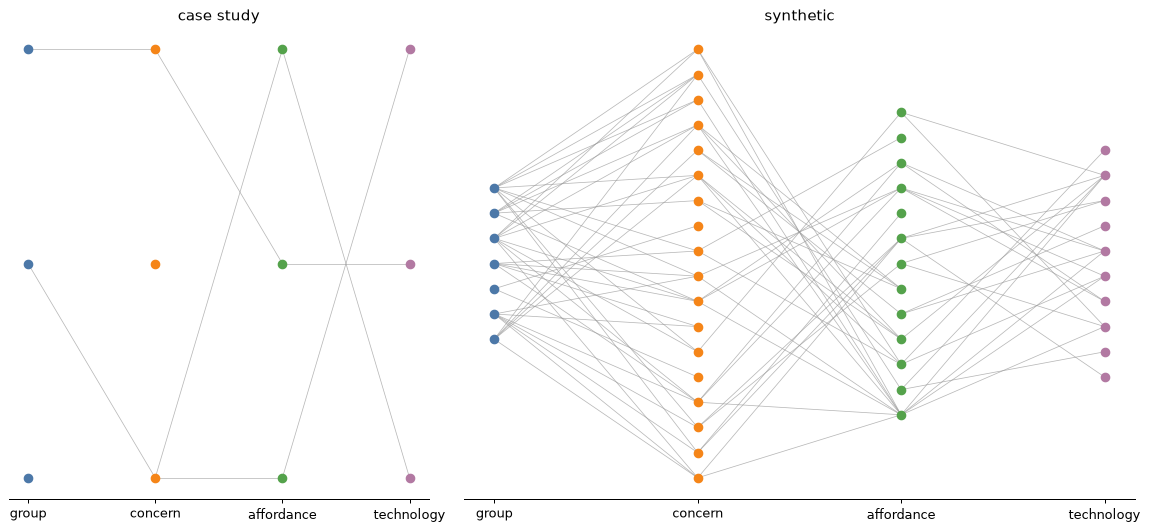

In [2]:
def draw_layered(ax, m, title):
    G = m.G
    pos = {}
    for x, layer in enumerate(sg_.LAYERS):
        ns = m.nodes(layer)
        for i, n in enumerate(ns):
            pos[n] = (x, -(i - (len(ns) - 1) / 2))
    for u, v, d in G.edges(data=True):
        ax.plot(*zip(pos[u], pos[v]), color="#999", lw=0.6, alpha=0.7, zorder=1)
    for layer in sg_.LAYERS:
        ns = m.nodes(layer)
        ax.scatter([pos[n][0] for n in ns], [pos[n][1] for n in ns], s=45, color=COLORS[layer], zorder=2, label=sg_.LAYER_LABEL[layer])
    ax.set_title(title); ax.set_xticks(range(4)); ax.set_xticklabels([sg_.LAYER_LABEL[l] for l in sg_.LAYERS]); ax.set_yticks([])
    ax.spines["left"].set_visible(False)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, (k, m) in zip(axes, VAULTS.items()):
    draw_layered(ax, m, k)
plt.tight_layout(); plt.show()

**Reads as:** the four layers as columns, one dot per page, one line per relation page. A dot with no line to its neighbouring column is a node the chain does not reach (see section 1).

**Does not mean:** position within a column is alphabetical, not importance; line count is the number of relation pages written, not how strongly anything is held or addressed.

## 1. Traceability chains and gaps

Borrowing from requirements traceability: for each concern, who holds it, which affordances address it, which technologies those are attributed to.

In [3]:
for k, m in VAULTS.items():
    print("=" * 20, k)
    tr = sg_.traceability(m)
    display(tr[["n_holders", "n_affordances", "n_technologies", "chain"]])
    print("Chain depth reached, by concern:"); display(tr["chain"].value_counts().to_frame("concerns"))
    print("Group coverage (concerns held, by how far each reaches):"); display(sg_.group_coverage(m))
    print("Nodes with no link to the neighbouring layer:")
    o = sg_.orphans(m)
    o["affordances attributed to no technology"] = [a for a in m.nodes("affordance") if m.G.out_degree(a) == 0]
    for lab, ns in o.items(): print(f"  {lab}: {ns if ns else 'none'}")

==================== case study


,n_holders,n_affordances,n_technologies,chain
concern,,,,
anonymity,1,1,1,complete
attribution,0,0,0,unaddressed
intent-without-drift,1,2,2,complete


Chain depth reached, by concern:


,concerns
chain,
complete,2
unaddressed,1


Group coverage (concerns held, by how far each reaches):


,concerns_held,complete,"addressed, no technology",unaddressed
group,,,,
facilitator-analysts,1,1,0,0
project-leads,1,1,0,0
workshop-participants,0,0,0,0


... (3 outputs left out)

,concerns
chain,
complete,15
unaddressed,3


Group coverage (concerns held, by how far each reaches):


,concerns_held,complete,"addressed, no technology",unaddressed
group,,,,
board-volunteers,9,9,0,0
farm-irrigators,5,5,0,0
household-members,8,8,0,0
maintenance-crew,5,4,0,1
school-liaisons,2,0,0,2
treatment-operators,6,5,0,1
watershed-stewards,5,5,0,0


Nodes with no link to the neighbouring layer:
  groups holding no concern: none
  concerns held by no group: none
  affordances addressing no concern: none
  technologies attributed to no affordance: none
  affordances attributed to no technology: ['community-asset-fund', 'operator-training-course', 'reserve-storage-policy']


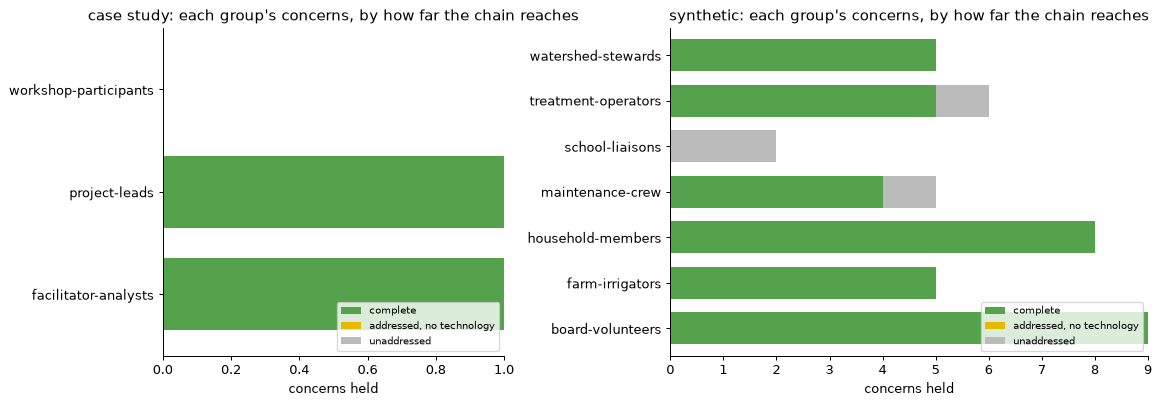

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
cols = {"complete": "#54a24b", "addressed, no technology": "#e6b800", "unaddressed": "#bbbbbb"}
for ax, (k, m) in zip(axes, VAULTS.items()):
    gc = sg_.group_coverage(m)[list(cols)]
    gc.plot.barh(stacked=True, ax=ax, color=list(cols.values()), width=0.7)
    ax.set_title(f"{k}: each group's concerns, by how far the chain reaches"); ax.set_ylabel(""); ax.set_xlabel("concerns held")
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Reads as:** bars show, for each group, how many held concerns have an affordance and a technology behind them (green), an affordance only (yellow), or nothing (grey).
A group with an all-grey bar holds concerns that no recorded affordance addresses. Affordances with no technology are listed above.

**Does not mean:** a grey or short bar is a gap in *what has been coded so far*, not a verdict that the group is neglected or the concern unmet; the vault may simply not have been coded further.
Having more green does not make a group, or an architecture, better served. An address link says a coder linked the two, not that it works.

## 2. Bipartite projections

Two one-mode views: groups linked when they hold the same concern, and concerns linked when the same affordance addresses both.
Edge weight is the number of shared neighbours.

case study | group projection: edges 0 , isolated groups ['facilitator-analysts', 'project-leads', 'workshop-participants'] | concern projection: edges 0 , components 3
synthetic | group projection: edges 13 , isolated groups ['school-liaisons'] | concern projection: edges 37 , components 6


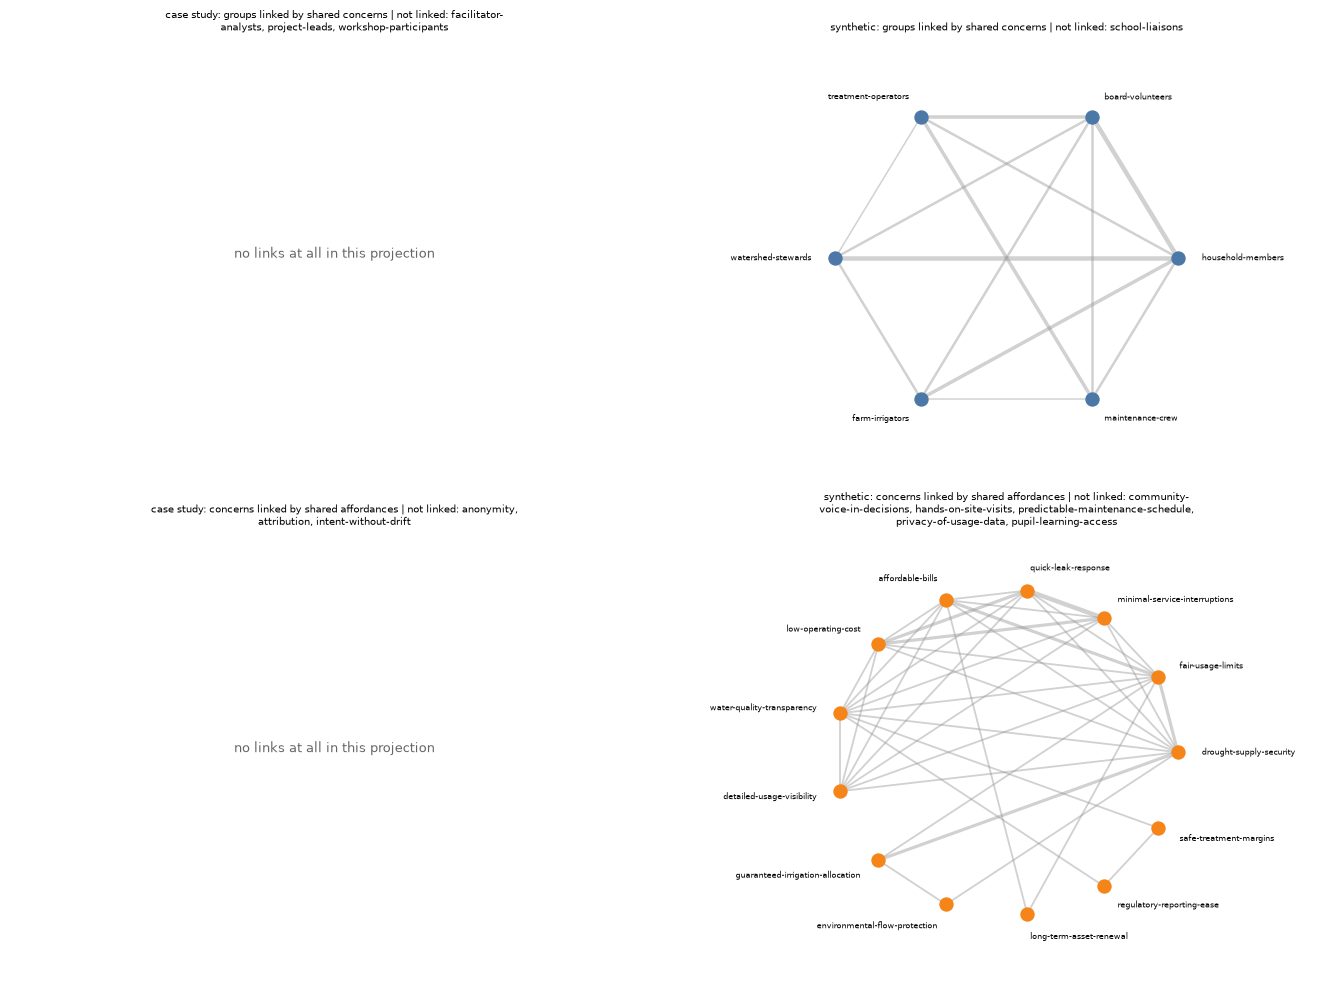

In [5]:
import numpy as np
def draw_proj(ax, B, title, color):
    iso = sorted(nx.isolates(B)); B = B.subgraph([n for n in B if n not in iso])
    ns = sorted(B, key=lambda n: (-B.degree(n, weight="weight"), n))      # ring order: by weighted degree, for readability only
    ang = {n: 2 * np.pi * i / max(len(ns), 1) for i, n in enumerate(ns)}
    pos = {n: (np.cos(a), np.sin(a)) for n, a in ang.items()}
    mx = max([d["weight"] for *_, d in B.edges(data=True)] or [1])
    nx.draw_networkx_edges(B, pos, ax=ax, width=[0.4 + 3.2 * d["weight"] / mx for *_, d in B.edges(data=True)], edge_color="#999999", alpha=0.45)
    nx.draw_networkx_nodes(B, pos, ax=ax, node_color=color, node_size=110)
    for n, (x, y) in pos.items():
        ax.text(1.14 * x, 1.14 * y, n, fontsize=6.5, ha="left" if x > 0.05 else "right" if x < -0.05 else "center", va="center")
    ax.set_xlim(-1.9, 1.9); ax.set_ylim(-1.35, 1.35)
    if not B.number_of_edges(): ax.text(0, 0, "no links at all in this projection", ha="center", color="#666666")
    ax.set_title(textwrap.fill(title + (" | not linked: " + ", ".join(iso) if iso else ""), 75), fontsize=8); ax.axis("off")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for j, (k, m) in enumerate(VAULTS.items()):
    Bg = sg_.projection(m, "stakeholder-group", "concern")
    Bc = sg_.projection(m, "concern", "affordance")
    draw_proj(axes[0, j], Bg, f"{k}: groups linked by shared concerns", COLORS["stakeholder-group"])
    draw_proj(axes[1, j], Bc, f"{k}: concerns linked by shared affordances", COLORS["concern"])
    print(k, "| group projection: edges", Bg.number_of_edges(), ", isolated groups", list(nx.isolates(Bg)),
          "| concern projection: edges", Bc.number_of_edges(), ", components", nx.number_connected_components(Bc))
plt.tight_layout(); plt.show()

In [6]:
m = VAULTS["synthetic"]
Bg = sg_.projection(m, "stakeholder-group", "concern")
shared = pd.DataFrame([(a, b, d["weight"], sorted(set(m.G.successors(a)) & set(m.G.successors(b)))) for a, b, d in Bg.edges(data=True)],
                      columns=["group_a", "group_b", "shared concerns", "which"]).sort_values(["shared concerns", "group_a"], ascending=[False, True])
display(shared)

,group_a,group_b,shared concerns,which
0,board-volunteers,household-members,4,"[affordable-bills, community-voice-in-decisions, fair-usage-limits, privacy-..."
8,household-members,watershed-stewards,4,"[community-voice-in-decisions, drought-supply-security, fair-usage-limits, w..."
4,board-volunteers,treatment-operators,3,"[low-operating-cost, regulatory-reporting-ease, safe-treatment-margins]"
5,farm-irrigators,household-members,3,"[community-voice-in-decisions, drought-supply-security, minimal-service-inte..."
11,maintenance-crew,treatment-operators,3,"[low-operating-cost, predictable-maintenance-schedule, quick-leak-response]"
1,board-volunteers,farm-irrigators,2,"[community-voice-in-decisions, detailed-usage-visibility]"
2,board-volunteers,watershed-stewards,2,"[community-voice-in-decisions, fair-usage-limits]"
3,board-volunteers,maintenance-crew,2,"[long-term-asset-renewal, low-operating-cost]"
6,farm-irrigators,watershed-stewards,2,"[community-voice-in-decisions, drought-supply-security]"
9,household-members,maintenance-crew,2,"[minimal-service-interruptions, quick-leak-response]"


**Reads as:** an edge between two groups means they hold at least one concern in common (the table names which). A cluster of concerns joined by thick edges are concerns served by the same affordances.
Isolated nodes share nothing with the rest.

**Does not mean:** shared concerns are not agreement; two groups may want the same thing for opposite reasons or at others' cost (see section 3). Projection loses information: a link says nothing about *which* node is the shared one, and a hub node makes a clique of its neighbours.
Nodes sit on a ring in order of weighted degree; ring position is a drawing convenience, not a measurement.

## 3. Tension: conflicts, and who stands where

`conflicts` are declared on a concern page. Here: every conflicting pair, the groups holding both sides (internal tension), and group pairs holding opposite sides.

In [7]:
for k, m in VAULTS.items():
    pairs, both, opp, one_sided = sg_.tension(m)
    print("=" * 20, k, f"| {len(pairs)} conflict pairs, {one_sided} declared on one page only (symmetric closure supplies the other direction)")
    display(pairs)
    print("Groups holding both sides of a pair:"); display(both if len(both) else "none")
    print("Group pairs on opposite sides:"); display(opp if len(opp) else "none")

==================== case study | 1 conflict pairs, 1 declared on one page only (symmetric closure supplies the other direction)


,concern_a,concern_b,declared_by,holders_a,holders_b
0,anonymity,attribution,anonymity,[facilitator-analysts],[]


Groups holding both sides of a pair:


'none'

Group pairs on opposite sides:


'none'

... (2 outputs left out)

Groups holding both sides of a pair:


,group,concern_a,concern_b
0,board-volunteers,affordable-bills,long-term-asset-renewal
1,board-volunteers,detailed-usage-visibility,privacy-of-usage-data
2,board-volunteers,low-operating-cost,safe-treatment-margins
3,treatment-operators,low-operating-cost,safe-treatment-margins


Group pairs on opposite sides:


,group_x,concern_x,group_y,concern_y
0,board-volunteers,affordable-bills,maintenance-crew,long-term-asset-renewal
1,household-members,affordable-bills,board-volunteers,long-term-asset-renewal
2,household-members,affordable-bills,maintenance-crew,long-term-asset-renewal
3,board-volunteers,detailed-usage-visibility,household-members,privacy-of-usage-data
4,farm-irrigators,detailed-usage-visibility,board-volunteers,privacy-of-usage-data
5,farm-irrigators,detailed-usage-visibility,household-members,privacy-of-usage-data
6,watershed-stewards,environmental-flow-protection,farm-irrigators,guaranteed-irrigation-allocation
7,board-volunteers,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation
8,household-members,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation
9,watershed-stewards,fair-usage-limits,farm-irrigators,guaranteed-irrigation-allocation


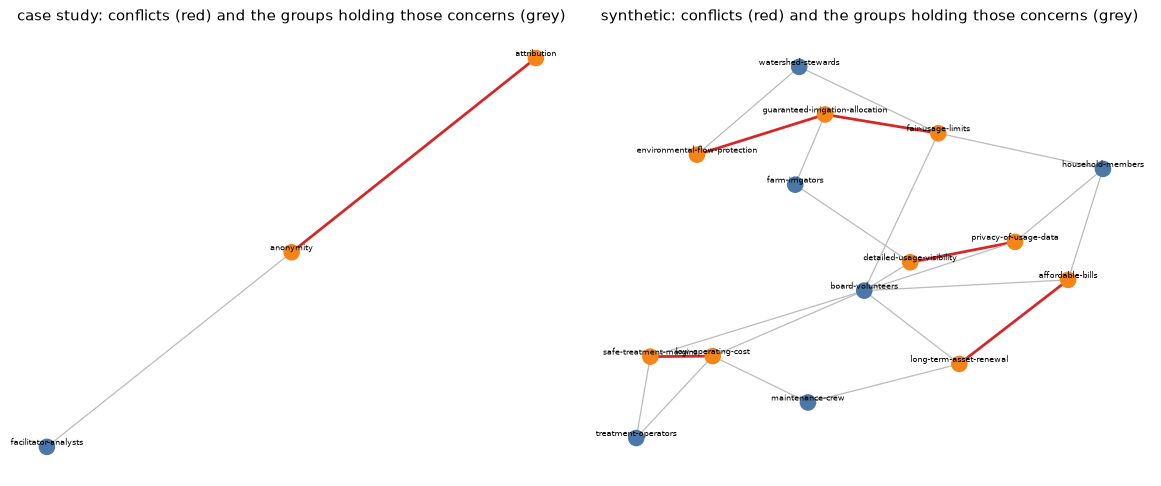

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (k, m) in zip(axes, VAULTS.items()):
    C = m.conflicts; G = m.G
    inv = nx.Graph(); inv.add_nodes_from(C.nodes); inv.add_edges_from(C.edges)
    inv_both = {g for g in m.nodes("stakeholder-group") if any(c in G[g] for c in C if C.degree(c))}
    # concerns in conflict, plus the groups holding them
    sub = nx.Graph(C.edges)
    for g in m.nodes("stakeholder-group"):
        for c in G.successors(g):
            if c in sub: sub.add_edge(g, c, held=True)
    pos = nx.spring_layout(sub, seed=4, k=0.9)
    nx.draw_networkx_edges(sub, pos, ax=ax, edgelist=[e for e in sub.edges if e in C.edges or e[::-1] in C.edges], edge_color="#d62728", width=2.2)
    nx.draw_networkx_edges(sub, pos, ax=ax, edgelist=[e for e in sub.edges if not (e in C.edges or e[::-1] in C.edges)], edge_color="#bbbbbb", width=1)
    nx.draw_networkx_nodes(sub, pos, ax=ax, node_color=[COLORS[G.nodes[n]["layer"]] for n in sub], node_size=150)
    nx.draw_networkx_labels(sub, pos, ax=ax, font_size=6.5, verticalalignment="bottom")
    ax.set_title(f"{k}: conflicts (red) and the groups holding those concerns (grey)"); ax.axis("off")
plt.tight_layout(); plt.show()

**Reads as:** red edges join concerns declared to conflict; grey edges join a group to a concern it holds. A group touching both ends of a red edge holds both sides itself; two groups touching opposite ends are on opposite sides.
In the tables, a group can appear in both lists.

**Does not mean:** a conflict is a declared tension between interests, not a disagreement that has occurred, and not a flaw to be removed. A group holding both sides is carrying a trade-off, not being inconsistent.
Opposite sides are not adversaries. A concern with no conflict edge may simply not have been compared with the others; absence of a declared conflict is not harmony.

## 4. Centrality and brokerage

Which affordances and technologies carry the most concerns? Three descriptive counts: concerns carried (every concern upstream of the node), groups behind it, and betweenness (the share of shortest paths between other nodes that pass through it, on the undirected typed graph).

==================== case study


,layer,concerns_carried,groups_behind,degree,betweenness
node,,,,,
gated-approval,affordance,1,1,2,0.073
revert-with-history-kept,affordance,1,1,2,0.073
groups-clustered-under-a-cap,affordance,1,1,2,0.036
archive-tags,technology,1,1,1,0.000
cap-setting,technology,1,1,1,0.000
main-and-dev-branches,technology,1,1,1,0.000


==================== synthetic


,layer,concerns_carried,groups_behind,degree,betweenness
node,,,,,
member-portal,technology,13,6,5,0.087
usage-data-warehouse,technology,10,6,3,0.031
sensor-telemetry-platform,technology,9,6,4,0.070
smart-meter-network,technology,9,6,3,0.019
usage-dashboard,affordance,8,6,12,0.240
public-quality-reports,affordance,3,4,6,0.094
tiered-tariff-schedule,affordance,3,4,5,0.056
leak-alert-notifications,affordance,3,5,6,0.048
seasonal-allocation-calendar,affordance,3,4,4,0.027


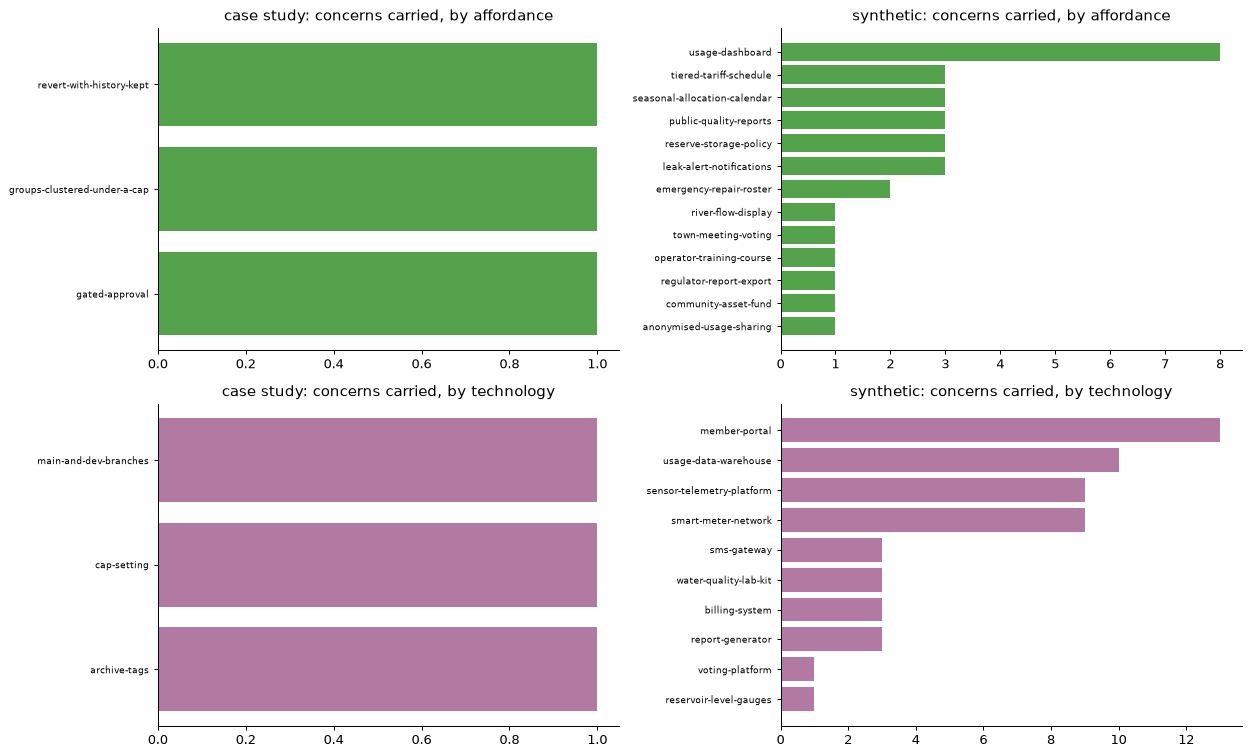

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
for j, (k, m) in enumerate(VAULTS.items()):
    cr = sg_.carriage(m)
    print("=" * 20, k); display(cr.sort_values(["concerns_carried", "betweenness"], ascending=False).head(10))
    for i, layer in enumerate(["affordance", "technology"]):
        d = cr[cr.layer == layer].sort_values("concerns_carried")
        axes[i, j].barh(d.index, d["concerns_carried"], color=COLORS[layer])
        axes[i, j].set_title(f"{k}: concerns carried, by {layer}"); axes[i, j].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

**Reads as:** a long bar is a node that many recorded concerns pass through on their way to something concrete: where the structure concentrates, so where a change would touch many concerns, and where a concern would have no other route. High betweenness says the node sits between otherwise separate parts of the graph (a broker). Zero betweenness (every leaf has it) only says no shortest path passes through the node.

**Does not mean:** carrying many concerns is not importance, quality or risk by itself, and carrying few is not weakness; the count depends on how finely concerns were written and how many records were coded. These are descriptions of this vault's coding, not properties of the real system.
Do not compare counts across the two vaults.

## 5. Community structure

Do the four layers fall into clusters that cut across them? Two standard algorithms on the undirected graph (greedy modularity, Louvain with a fixed seed), compared on how many same-cluster node pairs they agree on.

==================== case study | greedy modularity: 3 clusters, louvain (seed 1): 3 clusters | pair agreement between the two: 0.53
  cluster 0: groups ['facilitator-analysts'] | concerns 1 | affordances 1 | technologies 1
  cluster 1: groups ['project-leads'] | concerns 1 | affordances 1 | technologies 1
  cluster 2: groups [] | concerns 0 | affordances 1 | technologies 1
==================== synthetic | greedy modularity: 7 clusters, louvain (seed 1): 6 clusters | pair agreement between the two: 0.31
  cluster 0: groups [] | concerns 2 | affordances 4 | technologies 4
  cluster 1: groups ['treatment-operators'] | concerns 2 | affordances 3 | technologies 3
  cluster 2: groups ['farm-irrigators'] | concerns 4 | affordances 2 | technologies 0
  cluster 3: groups ['household-members', 'watershed-stewards'] | concerns 3 | affordances 1 | technologies 1
  cluster 4: groups ['board-volunteers', 'maintenance-crew'] | concerns 3 | affordances 1 | technologies 0
  cluster 5: groups [] | conc

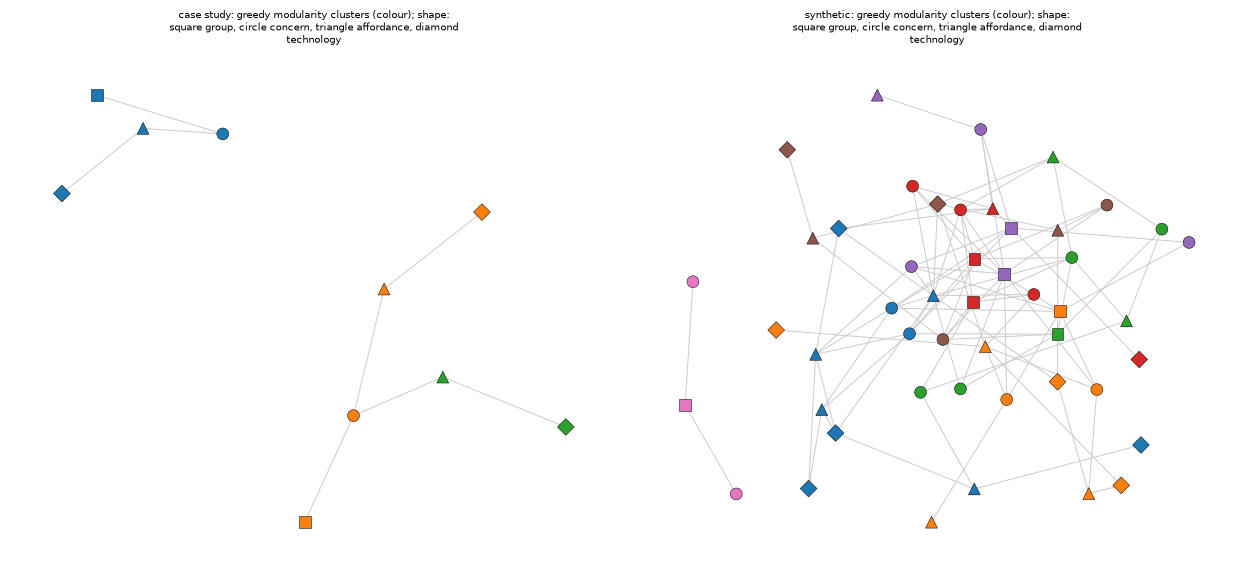

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (k, m) in zip(axes, VAULTS.items()):
    U, parts = sg_.communities(m)
    names = list(parts)
    agree = sg_.same_partition_pairs(parts[names[0]], parts[names[1]])
    print("=" * 20, k, "|", ", ".join(f"{n}: {len(p)} clusters" for n, p in parts.items()), f"| pair agreement between the two: {agree:.2f}")
    lab = {n: i for i, c in enumerate(parts[names[0]]) for n in c}
    pos = nx.spring_layout(U, seed=5, k=0.7)
    cmap = matplotlib.colormaps["tab10"]
    nx.draw_networkx_edges(U, pos, ax=ax, edge_color="#cccccc", width=0.8)
    for layer, shape in zip(sg_.LAYERS, "so^D"):
        ns = [n for n in U if U.nodes[n]["layer"] == layer]
        nx.draw_networkx_nodes(U, pos, nodelist=ns, ax=ax, node_shape=shape, node_size=90,
                               node_color=[cmap(lab[n] % 10) for n in ns], edgecolors="k", linewidths=0.4)
    ax.set_title(textwrap.fill(f"{k}: {names[0]} clusters (colour); shape: square group, circle concern, triangle affordance, diamond technology", 60), fontsize=8)
    ax.axis("off")
    for i, c in enumerate(parts[names[0]]):
        print(f"  cluster {i}: groups {sorted(x for x in c if U.nodes[x]['layer']=='stakeholder-group')} | concerns {sum(U.nodes[x]['layer']=='concern' for x in c)} | affordances {sum(U.nodes[x]['layer']=='affordance' for x in c)} | technologies {sum(U.nodes[x]['layer']=='technology' for x in c)}")
plt.tight_layout(); plt.show()

**Reads as:** each colour is a set of nodes that are more densely linked to each other than to the rest, typically one group with its concerns and the affordances and technologies behind them. Clusters that hold several groups are where groups share structure. Where the two algorithms agree on few pairs, the structure is not sharply clustered, and any one partition should be held loosely.

**Does not mean:** clusters are not teams, workstreams or architectures; they are a by-product of how the vault was coded, and a hub (see section 4) can pull otherwise distinct parts together. A cluster is not a better or worse grouping, and different algorithms or seeds give different partitions.

## 6. Provenance: what the coded records name

Each coded scenario or architecture record names groups, concerns, affordances and (architectures) technologies. Here: which concerns each record names, and which records name a conflicting pair together.

==================== case study


,kind,groups,concerns,affordances,technologies
record,,,,,
groups-under-a-cap-pitch-coded,architecture,0,1,1,1
two-branches-and-tags-pitch-coded,architecture,0,1,2,2
false-start-and-clean-restart-coded,scenario,1,1,2,0
notes-at-a-chatham-house-session-coded,scenario,2,2,1,0


Records naming both sides of a conflict: [('notes-at-a-chatham-house-session-coded', 'anonymity', 'attribution')]
==================== synthetic


,kind,groups,concerns,affordances,technologies
record,,,,,
lean-volunteer-pitch-coded,architecture,0,3,3,3
portal-first-pitch-coded,architecture,0,4,3,4
sensor-first-pitch-coded,architecture,0,4,3,4
budget-evening-coded,scenario,4,3,2,0
dry-july-allocation-talk-coded,scenario,3,4,3,0
night-main-break-coded,scenario,3,3,2,0
school-visit-day-coded,scenario,2,3,1,0


Records naming both sides of a conflict: none


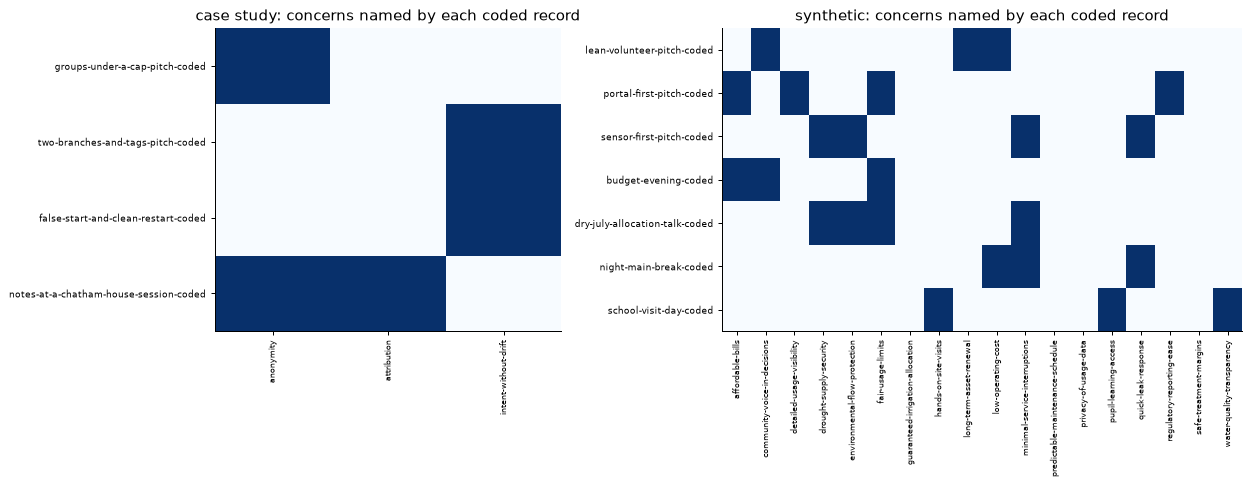

In [11]:
for k, m in VAULTS.items():
    R = m.records
    print("=" * 20, k); display(R.assign(**{c: R[c].map(len) for c in ["groups", "concerns", "affordances", "technologies"]})[["record", "kind", "groups", "concerns", "affordances", "technologies"]].set_index("record"))
    both = []
    for _, r in R.iterrows():
        both += [(r.record, a, b) for a, b in m.conflicts.edges if a in r.concerns and b in r.concerns]
    print("Records naming both sides of a conflict:", both if both else "none")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
for ax, (k, m) in zip(axes, VAULTS.items()):
    R = m.records; cs = m.nodes("concern")
    M = pd.DataFrame([[int(c in r) for c in cs] for r in R.concerns], index=R.record, columns=cs)
    ax.imshow(M.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(len(cs))); ax.set_xticklabels(cs, rotation=90, fontsize=6.5)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=7); ax.set_title(f"{k}: concerns named by each coded record")
plt.tight_layout(); plt.show()

**Reads as:** dark cells are concerns a record names. Columns with no dark cell are concerns no coded record mentions; rows show how much of the vault each record touches. Records that name both sides of a conflict are where that tension surfaces in the evidence.

**Does not mean:** a record naming more concerns is not a fuller or better account, and an architecture naming fewer is not narrower in any judged sense; records differ in what they were written to cover. Coverage here is of what was coded, not of the real world.

## What this notebook needed from `scat_kg`

- `scat_kg.vault.read_vault` (internal): the only way to obtain parsed pages and links; the public API has no loader.
- Nothing else beyond `Page.type`, `.name`, `.status`, `.fields["title"]` and `.fm_links`.
- Everything else (typed graph, symmetric conflicts, flattened relations, record table) was rebuilt here; see `../readout.md` for what the tools could provide instead.